# 06 · Pre-etiquetado de la función de cita

Se toma el archivo `citations_dataset.json` y asigna a cada contexto de cita una pre-etiqueta de función de cita (9 categorías) usando 3 LLMs de pesos abiertos como **jueces**.

La categoría final se elige por **bootstrap** entre los votos de los jueces:

| Acuerdo | Significado |
|---|---|
| `unanimous` | todos los jueces dan la misma categoría |
| `bootstrap` | hay desacuerdo y la categoría final sale del bootstrap |
| `unlabeled` | ningún juez respondió (se reintenta al volver a ejecutar) |


## 1. Conexión con los directorios

In [1]:
import os
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
%%bash
apt-get update && apt-get install -y zstd
curl -fsSL https://ollama.com/install.sh | sh

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.7 kB]
Get:6 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,089 kB]
Hit:7 http://archive.ubuntu.com/ubuntu noble InRelease
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:9 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,149 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-upd

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [3]:
%%bash
ollama serve > ollama.log 2>&1 &
sleep 5

In [4]:
%%bash
echo "Descargando llama3.1:8b..."
ollama pull llama3.1:8b

echo "Descargando qwen2.5:7b..."
ollama pull qwen2.5:7b

echo "Descargando mistral-nemo..."
ollama pull mistral-nemo

echo "¡Ollama y los modelos están listos en la GPU!"

Descargando llama3.1:8b...
Descargando qwen2.5:7b...
Descargando mistral-nemo...
¡Ollama y los modelos están listos en la GPU!


pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest 
pulling 667b0c1932bc:   1% ▕                  ▏  33 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:   3% ▕                  ▏ 172 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:   5% ▕                  ▏ 245 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:   8% ▕█                 ▏ 389 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:   9% ▕█                 ▏ 453 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:  12% ▕██                ▏ 585 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:  15% ▕██                ▏ 717 MB/4.9 GB                  pulling manifest 
pulling 667b0c1932bc:  16% ▕██                ▏ 780 MB/4.9 GB              

## 2. Parámetros de entrada



In [3]:
DRIVE_DIR = "/content/drive/MyDrive/Colab Notebooks/proyecto"
INPUT_PATH = f"{DRIVE_DIR}/data/citations_dataset.json"
OUTPUT_PATH = f"{DRIVE_DIR}/data/citations_labeled_v2.json"

JUDGES = [
    "llama3=llama3.1:8b@http://localhost:11434/v1",
    "qwen=qwen2.5:7b@http://localhost:11434/v1",
    "mistral=mistral-nemo@http://localhost:11434/v1",
]

RUNS = 1 # Número de consultas por juez y cita
WORKERS = 3 # Número de consultas en paralelo
TEMPERATURE = 0.1
MAX_TOKENS = 120
TIMEOUT = 120
RETRIES = 3
JSON_MODE = False
CONTEXT_ONLY = False

PROMPT_VERSION = "v1"

BOOTSTRAP_WEIGHTED = False
BOOTSTRAP_SAMPLES = 2000
SEED = 13

FILL_SELECTED = True # Copiar la etiqueta final en selected_function (annotator="llm-ensemble") si están vacíos
TARGET_PER_CLASS = 2000

LIMIT = 0 # Procesar solo las primeras N citas (0 = todas)
DRY_RUN = False

## 3. Claves de API
- `LLM_API_KEY`: clave de los jueces LLM).

In [4]:
def load_secret(name):
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            os.environ[name] = value
            return True
    except Exception:
        pass
    return bool(os.environ.get(name))

print(f"LLM_API_KEY: {'OK' if load_secret('LLM_API_KEY') else 'Sin llave'}")

LLM_API_KEY: Sin llave


## 4. Dependencias y categorías



In [5]:
import hashlib
import itertools
import json
import math
import os
import random
import re
import sys
import time
import urllib.error
import urllib.request
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from functools import lru_cache, partial
from types import SimpleNamespace

CATEGORIES = [
    ("Background",
     "Citations used to provide context, summarize the general background of a research topic, or trace the history of a field or idea. These citations lay the foundation for understanding the focal study.",
     ["Reviews existing literature to ensure comprehensiveness.",
      "Cites review papers or relevant previous studies to depict the current state of the field.",
      "Highlights important or prevailing findings in the field.",
      "Traces the historical development or presents key ideas in the subject area.",
      "Do NOT use when the present work is said to be built on the cited work (Basis), when the sentence "
      "credits who first introduced an idea (Identification of the Originator), when it sends the reader to "
      "the source for details (Further Reading), or when it stresses what is missing (Gap)."]),
    ("Gap",
     "Citations that help identify research gaps or unexplored areas, justifying the author’s choice of research topic.",
     ["Highlights what has or has not been done in the research area.",
      "Identifies gaps in knowledge or areas for further study.",
      "Justifies the relevance and importance of the current research by contrasting it with existing work.",
      "Do NOT use when the sentence neutrally summarizes prior work (Background), or when it contrasts "
      "methods or results without saying that something is missing (Comparison)."]),
    ("Basis",
     "Citations that provide a foundation for the current research. This can operate at a macro level (broad influence) or a micro level (specific key contributions).",
     ["Serves as the intellectual starting point for the focal research.",
      "The cited work significantly shapes the research idea or hypothesis.",
      "The focal research builds upon, continues, or expands on the cited work.",
      "Do NOT use for general related work (Background); when a concrete method, tool, model or dataset is "
      "used unchanged (Application) or changed (Improvement/Modification); or when the sentence only credits "
      "who first introduced an idea (Identification of the Originator)."]),
    ("Comparison",
     "Citations used to compare the current work with cited studies or to draw comparisons between cited studies.",
     ["Highlights similarities or differences between the current research and cited works.",
      "Compares methodologies, findings, algorithms, data, or theoretical concepts.",
      "May point out advantages of the current study over previous ones or establish links among different cited works.",
      "Do NOT use when a cited result is only offered to back up a claim (Evidence), or when the sentence "
      "only points out what is missing (Gap)."]),
    ("Application",
     "Citations that directly employ a method, technique, or tool from the cited work without modification.",
     ["Utilizes existing methods, algorithms, instruments, or data for the current research.",
      "Employs the cited work as a practical tool (e.g., equations, analysis methods) for calculation or experimentation.",
      "Applies the cited method without modification.",
      "Do NOT use when the cited method is changed (Improvement/Modification); when the cited work is only "
      "mentioned to justify a choice (Evidence); or when the sentence is mainly about who first introduced "
      "the method (Identification of the Originator)."]),
    ("Improvement/Modification",
     "Citations in which methods or tools from the cited work are adapted, expanded, or modified for the current research.",
     ["The cited method is adapted, improved, or extended to fit new experimental conditions or research objectives.",
      "Uses the cited work as a foundation but modifies it to enhance precision or scope.",
      "Do NOT use when the method is used unchanged (Application), or when only ideas or theory are "
      "built upon, with no method or tool being changed (Basis)."]),
    ("Evidence",
     "Citations used to support claims, hypotheses, or findings in the current research.",
     ["Supports arguments, hypotheses, or factual statements.",
      "Justifies research design, methodologies, or experimental procedures.",
      "Substantiates or explains findings, especially in the discussion section.",
      "Provides evidence to mitigate limitations or support further research suggestions.",
      "Do NOT use when the cited method, tool or data is actually applied in this work (Application), or when "
      "the point of the sentence is that results, methods or data agree or differ (Comparison)."]),
    ("Identification of the Originator",
     "Citations used to acknowledge the original source of an idea, concept, method, or theory.",
     ["Identifies the original publication where a key idea or method was first introduced.",
      "Acknowledges pioneers in the field.",
      "Gives credit to the priority of a cited work, demonstrating intellectual indebtedness.",
      "Do NOT use for a neutral summary of the field with no credit for first introduction (Background), or "
      "when the main point is that the idea or method is used in this work (Application)."]),
    ("Further Reading",
     "Citations that direct readers to additional or supplementary literature for more detailed information or context.",
     ["Alerts readers to new, different, or relevant sources of information.",
      "Provides more complete details on data, methods, or background not fully covered in the current work.",
      "Often used to refer readers to external sources for deeper insights.",
      "Do NOT use when the sentence itself summarizes the content of the cited work as context (Background), "
      "or when the cited method is used in this work (Application)."]),
]

LABELS = [c[0] for c in CATEGORIES]
DEFS = {c[0]: c for c in CATEGORIES}


def norm(s):
    return re.sub(r"[^a-z]", "", str(s).lower())


ALIASES = {norm(l): l for l in LABELS}
ALIASES.update({"improvement": "Improvement/Modification", "modification": "Improvement/Modification",
                "improvementmodification": "Improvement/Modification",
                "originator": "Identification of the Originator",
                "identificationoforiginator": "Identification of the Originator",
                "identification": "Identification of the Originator",
                "furtherreading": "Further Reading"})

## 5. Prompts y análisis de respuestas

In [ ]:
def system_prompt(order):
    lines = ["You are an expert annotator of scientific literature. Your task is to decide "
             "the citation function: the rhetorical purpose for which the citing authors "
             "use the cited paper in the text.", "",
             "Categories (each with its criteria and when NOT to use it):"]
    for name in order:
        _, definition, criteria = DEFS[name]
        lines.append(f"- {name}: {definition}")
        lines.extend(f"    * {c}" for c in criteria)
    lines += ["",
              "Rules:",
              "- Classify ONLY the citation marked #CITATION_TAG. #OTHER_CITATION marks other citations "
              "in the text and must be ignored.",
              "- Decide by how the citing authors use the cited paper in the text. The cited paper's title "
              "and abstract only help you understand what that paper contributes; they do not decide the category.",
              "- Choose exactly ONE category.",
              "- CRITICAL: Do not use Background as a default choice. If there is any mention of methodology, comparison, or evidence, prefer those specific classes over Background.",
              f"- The value of \"function\" must be exactly one of: {' | '.join(order)}.",
              "- \"confidence\" is a decimal between 0.0 and 1.0 (for example 0.85), not a percentage.",
              "- Answer ONLY with a JSON object and no other text: "
              "{\"function\": \"<category name>\", \"confidence\": <decimal>}"]
    return "\n".join(lines)

def _field(value):
    value = value.strip() if isinstance(value, str) else ""
    return value or "(not available)"


def context_text(rec, context_only):
    parts = [f"Text before the citing sentence: {_field(rec.get('left_context'))}",
             f"Citing sentence: {_field(rec.get('citing_sentence'))}",
             f"Text after the citing sentence: {_field(rec.get('right_context'))}"]
    if not context_only:
        parts += [f"Cited paper title: {_field(rec.get('cited_title'))}",
                  f"Cited paper abstract: {_field(rec.get('cited_abstract'))}"]
    return "\n\n".join(parts)


def user_prompt(rec, context_only):
    return (context_text(rec, context_only) + "\n\nWhich citation function does the #CITATION_TAG citation have? Answer with the JSON object only.")


def parse_answer(text):
    label = conf = None
    text = text if isinstance(text, str) else ""
    m = re.search(r"\{.*?\}", text, re.S)
    if m:
        try:
            obj = json.loads(m.group(0))
            raw = obj.get("function") or obj.get("label") or obj.get("category")
            label = ALIASES.get(norm(raw)) if raw is not None else None
            c = obj.get("confidence")
            if c is not None:
                c = float(c)
                if 1 < c <= 100:
                    c /= 100
                conf = min(1.0, max(0.0, c))
        except (ValueError, TypeError, AttributeError):
            pass
    if label is None:
        found = {l for l in LABELS
                 if re.search(r"(?<![A-Za-z])" + re.escape(l) + r"(?![A-Za-z])", text, re.I)}
        label = next(iter(found)) if len(found) == 1 else None
    return label, conf

## 6. Jueces: LLMs de pesos abiertos

In [7]:
class Judge:
    def __init__(self, spec, args):
        if "=" not in spec:
            raise ValueError(f"--judge debe tener la forma NOMBRE=MODELO@URL (recibido: {spec})")
        self.name, rest = (s.strip() for s in spec.split("=", 1))
        if "@" not in rest:
            raise ValueError(f"--judge {spec}: falta @URL_BASE")
        self.model, url = rest.rsplit("@", 1)
        self.url = url.rstrip("/") + "/chat/completions"
        self.args = args

    def ask(self, system, user, rec):
        a = self.args
        payload = {"model": self.model, "temperature": a.temperature, "max_tokens": a.max_tokens,
                   "messages": [{"role": "system", "content": system},
                                {"role": "user", "content": user}]}
        if a.json_mode:
            payload["response_format"] = {"type": "json_object"}
        headers = {"Content-Type": "application/json",
                   "Authorization": f"Bearer {os.environ.get('LLM_API_KEY', 'EMPTY')}"}
        last = None
        for attempt in range(a.retries):
            try:
                req = urllib.request.Request(self.url, json.dumps(payload).encode(), headers)
                with urllib.request.urlopen(req, timeout=a.timeout) as r:
                    return json.load(r)["choices"][0]["message"]["content"] or ""
            except (urllib.error.URLError, TimeoutError, KeyError, ValueError, OSError) as e:
                last = e
                time.sleep(2 ** attempt)
        raise RuntimeError(f"{self.name}: {type(last).__name__}: {last}")

## 7. Utilidades: claves, JSON, caché y ejecución en paralelo

In [8]:
def record_key(rec):
    raw = "|".join(str(rec.get(k, "")) for k in ("citing_arxiv_id", "cited_arxiv_id", "citing_sentence"))
    return hashlib.sha1(raw.encode("utf-8")).hexdigest()[:16]


def write_json(path, obj):
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    with open(path + ".part", "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)
    os.replace(path + ".part", path)


LEGACY_PROMPT_VERSION = "v1"


def load_cache(path, version):
    cache = {}
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            for line in f:
                try:
                    d = json.loads(line)
                    if d.get("prompt_version", LEGACY_PROMPT_VERSION) != version:
                        continue
                    cache[(d["key"], d["judge"], d["run"])] = d
                except (ValueError, KeyError):
                    continue
    return cache


def run_task(judge, rec, key, run, order, args):
    raw = judge.ask(system_prompt(order), user_prompt(rec, args.context_only), rec)
    label, conf = parse_answer(raw)
    return {"key": key, "judge": judge.name, "run": run, "label": label, "confidence": conf,
            "raw": None if label else (raw or "")[:200], "prompt_version": args.prompt_version}


def run_parallel(jobs, cache, cache_file, workers, desc):
    failures = 0
    if not jobs:
        return 0
    with ThreadPoolExecutor(workers) as pool:
        futs = [pool.submit(j) for j in jobs]
        for i, fut in enumerate(as_completed(futs), 1):
            try:
                res = fut.result()
            except RuntimeError as e:
                failures += 1
                print(f"  ERROR: {e}", file=sys.stderr)
                continue
            cache[(res["key"], res["judge"], res["run"])] = res
            cache_file.write(json.dumps(res, ensure_ascii=False) + "\n")
            cache_file.flush()
            if i % 50 == 0 or i == len(jobs):
                print(f"  {desc}: {i}/{len(jobs)}")
    return failures

## 8. Votos, bootstrap y decisión final

In [9]:
def judge_verdict(entries):
    votes = [e["label"] for e in entries if e["label"]]
    if not votes:
        return {"function": None, "confidence": None, "stability": 0.0}
    top, n = Counter(votes).most_common(1)[0]
    confs = [e["confidence"] for e in entries if e["label"] == top and e["confidence"] is not None]
    return {"function": top, "confidence": round(sum(confs) / len(confs), 3) if confs else None,
            "stability": round(n / len(entries), 3)}


EXACT_LIMIT = 5000


@lru_cache(maxsize=None)
def _exact_shares(pattern, weights):
    n = len(pattern)
    shares = defaultdict(float)
    for idx in itertools.product(range(n), repeat=n):
        tot = defaultdict(float)
        for i in idx:
            tot[pattern[i]] += weights[i]
        top = max(tot.values())
        winners = [l for l, v in tot.items() if v > top - 1e-12]
        for l in winners:
            shares[l] += 1.0 / len(winners)
    return {l: v / n ** n for l, v in shares.items()}


def bootstrap_shares(votes, weights, n_boot, seed):
    names = sorted(votes)
    uniq = {}
    pattern = tuple(uniq.setdefault(votes[j], len(uniq)) for j in names)
    w = tuple(round(weights[j], 2) for j in names)
    n = len(names)
    if n ** n <= EXACT_LIMIT:
        raw, method = _exact_shares(pattern, w), "exact"
    else:
        rng, acc = random.Random(seed), defaultdict(float)
        for _ in range(n_boot):
            tot = defaultdict(float)
            for _i in range(n):
                i = rng.randrange(n)
                tot[pattern[i]] += w[i]
            top = max(tot.values())
            winners = [l for l, v in tot.items() if v > top - 1e-12]
            for l in winners:
                acc[l] += 1.0 / len(winners)
        raw, method = {l: v / n_boot for l, v in acc.items()}, "montecarlo"
    inv = {v: k for k, v in uniq.items()}
    return {inv[i]: v for i, v in raw.items()}, method


def decide(verdicts, weighted, n_boot, seed):
    votes = {j: v["function"] for j, v in verdicts.items() if v["function"]}
    if not votes:
        return "", "unlabeled", None, {}, None
    conf = {j: (verdicts[j]["confidence"] if verdicts[j]["confidence"] is not None else 0.5) for j in votes}
    shares, method = bootstrap_shares(votes, conf if weighted else {j: 1.0 for j in votes}, n_boot, seed)
    best = max(shares.values())
    tied = [l for l, v in shares.items() if v > best - 1e-9]
    if len(tied) == 1:
        label = tied[0]
    else:
        label = max(tied, key=lambda l: (sum(conf[j] for j, x in votes.items() if x == l), -LABELS.index(l)))
    unanimous = len(set(votes.values())) == 1 and len(votes) == len(verdicts)
    return (label, "unanimous" if unanimous else "bootstrap", round(shares[label], 3),
            dict(Counter(votes.values())),
            {"method": method, "shares": {l: round(v, 3) for l, v in sorted(shares.items(), key=lambda x: -x[1])}})

## 9. Métricas de acuerdo e informe

In [ ]:
def cohen_kappa(a, b):
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[l] * cb[l] for l in set(ca) | set(cb)) / (n * n)
    return (po - pe) / (1 - pe) if pe < 1 else 1.0


def fleiss_kappa(rows):
    N, n = len(rows), len(rows[0]) if rows else 0
    if N == 0 or n < 2:
        return float("nan")
    cats = sorted({v for r in rows for v in r})
    counts = [Counter(r) for r in rows]
    p_i = [(sum(c[k] ** 2 for k in cats) - n) / (n * (n - 1)) for c in counts]
    p_j = [sum(c[k] for c in counts) / (N * n) for k in cats]
    pe = sum(p * p for p in p_j)
    pbar = sum(p_i) / N
    return (pbar - pe) / (1 - pe) if pe < 1 else 1.0


def print_report(records, names, target):
    tiers = Counter(r["prelabel_agreement"] for r in records)
    print(f"\nAcuerdo entre jueces ({len(records)} citas)")
    print("  " + " | ".join(f"{t}: {tiers.get(t, 0)}" for t in ("unanimous", "bootstrap", "unlabeled")))
    for i in range(len(names)):
        for k in range(i + 1, len(names)):
            pairs = [(r["prelabel_judges"][names[i]]["function"], r["prelabel_judges"][names[k]]["function"])
                     for r in records]
            pairs = [(x, y) for x, y in pairs if x and y]
            print(f"  Cohen {names[i]} vs {names[k]}: {cohen_kappa([p[0] for p in pairs], [p[1] for p in pairs]):.3f} (n={len(pairs)})")
    full = [[r["prelabel_judges"][n]["function"] for n in names] for r in records]
    full = [row for row in full if all(row)]
    if len(names) >= 3:
        print(f"  Fleiss ({len(names)} jueces): {fleiss_kappa(full):.3f} (n={len(full)})")
    disputed = [r for r in records if r["prelabel_agreement"] == "bootstrap"]
    if disputed:
        shares = [r["prelabel_confidence"] for r in disputed if r["prelabel_confidence"] is not None]
        changed = 0
        for r in disputed:
            top = max(r["prelabel_votes"].values())
            lead = [l for l, v in r["prelabel_votes"].items() if v == top]
            changed += len(lead) == 1 and lead[0] != r["prelabel_function"]
        print(f"\nBootstrap ({len(disputed)} citas con desacuerdo)")
        print(f"  proporción de victorias media de la categoría elegida: {sum(shares) / len(shares):.3f}")
        print(f"  difiere de la pluralidad simple (cuando existe una única): {changed}")
        if "jev" in names:
            same = sum(1 for r in disputed if r["prelabel_judges"]["jev"]["function"] == r["prelabel_function"])
            print(f"  la categoría final coincide con el voto de Jev: {same}/{len(disputed)}")
    print(f"\nCobertura por categoría (objetivo: {target})")
    by = defaultdict(Counter)
    for r in records:
        if r.get("selected_function"):
            by[r["selected_function"]][r["prelabel_agreement"]] += 1
    for l in LABELS:
        c = by[l]
        tot = sum(c.values())
        print(f"  {l:34s} total {tot:6d} (unanimous {c['unanimous']}, bootstrap {c['bootstrap']})  "
              f"{'OK' if tot >= target else f'faltan {target - tot}'}")

## 10. Ejecución



In [ ]:
def build_args():
    return SimpleNamespace(
        input=INPUT_PATH, output=OUTPUT_PATH, judge=list(JUDGES), runs=RUNS, workers=WORKERS,
        temperature=TEMPERATURE, max_tokens=MAX_TOKENS, timeout=TIMEOUT, retries=RETRIES,
        json_mode=JSON_MODE, context_only=CONTEXT_ONLY, bootstrap_weighted=BOOTSTRAP_WEIGHTED,
        bootstrap_samples=BOOTSTRAP_SAMPLES, seed=SEED, fill_selected=FILL_SELECTED,
        target_per_class=TARGET_PER_CLASS, limit=LIMIT, dry_run=DRY_RUN, prompt_version=PROMPT_VERSION)


def main():
    args = build_args()

    if not os.path.exists(args.input):
        raise FileNotFoundError(f"No existe el archivo de entrada: {args.input}\n¿Está montado Drive y es correcta la ruta INPUT_PATH?")
    with open(args.input, encoding="utf-8") as f:
        records = json.load(f)
    if args.limit:
        records = records[:args.limit]
    if not records:
        raise ValueError("El archivo de entrada no contiene citas.")

    orders = [list(LABELS)]
    for r in range(1, args.runs):
        o = list(LABELS)
        random.Random(r).shuffle(o)
        orders.append(o)

    if args.dry_run:
        print(system_prompt(orders[0]), "\n\n--- USER ---\n", user_prompt(records[0], args.context_only), sep="")
        return None
    if not args.judge:
        raise ValueError("Defina al menos un juez en JUDGES.")
    judges = [Judge(s, args) for s in args.judge]
    if len({j.name for j in judges}) != len(judges):
        raise ValueError("Los nombres de los jueces deben ser únicos.")

    names = [j.name for j in judges]
    keys = [record_key(r) for r in records]
    cache_path = args.output + ".judge_cache.jsonl"
    cache = load_cache(cache_path, args.prompt_version)
    todo = [(j, rec, k, run) for rec, k in zip(records, keys) for j in judges for run in range(args.runs)
            if (k, j.name, run) not in cache]
    print(f"{len(records)} citas | prompt {args.prompt_version} | jueces: {', '.join(names)} | "
          f"consultas pendientes a jueces LLM: {len(todo)} (en caché: {len(cache)})")

    def verdicts_of(k):
        v = {j.name: judge_verdict([cache[(k, j.name, r)] for r in range(args.runs)
                                    if (k, j.name, r) in cache]) for j in judges}
        return v

    os.makedirs(os.path.dirname(os.path.abspath(cache_path)), exist_ok=True)
    failures = 0
    with open(cache_path, "a", encoding="utf-8") as cf:
        jobs = [partial(run_task, j, rec, k, run, orders[run], args) for j, rec, k, run in todo]
        failures += run_parallel(jobs, cache, cf, args.workers, "jueces")

    previas = {}
    if os.path.exists(args.output):
        try:
            with open(args.output, encoding="utf-8") as f:
                for old in json.load(f):
                    if old.get("selected_function"):
                        previas[old.get("record_key")] = (old["selected_function"], old.get("annotator", ""))
        except (ValueError, OSError):
            previas = {}

    out = []
    for rec, k in zip(records, keys):
        verdicts = verdicts_of(k)
        label, tier, conf, votes, detail = decide(verdicts, args.bootstrap_weighted, args.bootstrap_samples, args.seed)
        new = dict(rec)
        if k in previas:
            new["selected_function"], new["annotator"] = previas[k]
        elif args.fill_selected and label and not new.get("selected_function") and not new.get("annotator"):
            new["selected_function"], new["annotator"] = label, "llm-ensemble"
        new.update({"prelabel_function": label, "prelabel_agreement": tier, "prelabel_confidence": conf,
                    "prelabel_votes": votes, "prelabel_bootstrap": detail,
                    "prelabel_judges": verdicts, "record_key": k,
                    "prompt_version": args.prompt_version})
        out.append(new)

    write_json(args.output, out)
    print_report(out, names, args.target_per_class)
    unlabeled = sum(1 for r in out if not r["prelabel_function"])
    print(f"\nSalida: {args.output}")
    if unlabeled:
        print(f"-> {unlabeled} citas sin etiqueta (ningún juez respondió). Vuelva a ejecutar para reintentarlas.", file=sys.stderr)
    if failures:
        print(f"-> {failures} consultas fallaron; vuelva a ejecutar para reintentarlas.", file=sys.stderr)
    return out

results = main()

13243 citas | prompt v1 | jueces: llama3, qwen, mistral | consultas pendientes a jueces LLM: 0 (en caché: 39402)

Acuerdo entre jueces (13243 citas)
  unanimous: 4995 | bootstrap: 8248 | unlabeled: 0
  Cohen llama3 vs qwen: 0.402 (n=13229)
  Cohen llama3 vs mistral: 0.434 (n=13235)
  Cohen qwen vs mistral: 0.479 (n=13225)
  Fleiss (3 jueces): 0.434 (n=13225)

== Bootstrap (8248 citas con desacuerdo) ==
  proporción de victorias media de la categoría elegida: 0.638
  difiere de la pluralidad simple (cuando existe una única): 0

Cobertura por categoría (objetivo: 2000)
  Background                         total   2193 (unanimous 744, bootstrap 1449)  OK
  Gap                                total    935 (unanimous 242, bootstrap 693)  faltan 1065
  Basis                              total   1677 (unanimous 344, bootstrap 1333)  faltan 323
  Comparison                         total   2128 (unanimous 898, bootstrap 1230)  OK
  Application                        total   2106 (unanimous 1118,

## 11. Resultados



In [21]:
import json
import os
import time
from collections import Counter, defaultdict
import pandas as pd

if os.path.exists(OUTPUT_PATH):
    with open(OUTPUT_PATH, encoding="utf-8") as f:
        results = json.load(f)
    print(f"Archivo: {OUTPUT_PATH}")
    print(f"Última modificación: {time.ctime(os.path.getmtime(OUTPUT_PATH))}")
elif "results" not in globals():
    results = []

print(f"Citas cargadas: {len(results)} | con selected_function: {sum(1 for r in results if r.get('selected_function'))}")
print("annotator:", dict(Counter(r.get("annotator") or "(vacío)" for r in results)))

Archivo: /content/drive/MyDrive/Colab Notebooks/proyecto/data/citations_labeled_v2.json
Última modificación: Fri Nov 20 06:01:19 2026
Citas cargadas: 13243 | con selected_function: 13243
annotator: {'llm-ensemble': 12198, 'fredygamez': 470, 'ca.torres': 575}


In [22]:
import pandas as pd
from collections import Counter

print("ACUERDO ENTRE JUECES")
if 'results' in globals() and results:
    names = [j.split("=")[0] for j in JUDGES]
    tiers = Counter(r["prelabel_agreement"] for r in results)

    votos_2_1 = 0
    votos_3_distintos = 0

    for r in results:
        if r["prelabel_agreement"] == "bootstrap":
            votos = [r["prelabel_judges"][n]["function"] for n in names if r["prelabel_judges"].get(n) and r["prelabel_judges"][n]["function"]]
            counts = Counter(votos)
            if len(counts) == 2:
                votos_2_1 += 1
            elif len(counts) == 3:
                votos_3_distintos += 1

    cohen_vals = []
    for i in range(len(names)):
        for k in range(i + 1, len(names)):
            pairs = [(r["prelabel_judges"][names[i]]["function"], r["prelabel_judges"][names[k]]["function"])
                     for r in results if r["prelabel_judges"].get(names[i]) and r["prelabel_judges"].get(names[k])]
            pairs = [(x, y) for x, y in pairs if x and y]
            val = cohen_kappa([p[0] for p in pairs], [p[1] for p in pairs]) if pairs else float('nan')
            cohen_vals.append((f"Cohen {names[i]} vs {names[k]}", round(val, 3), f"n={len(pairs)}"))

    full = [[r["prelabel_judges"][n]["function"] for n in names] for r in results]
    full = [row for row in full if all(row)]
    fleiss_val = fleiss_kappa(full) if len(names) >= 3 else float('nan')

    metricas = [
        ("Citas Unánimes (unanimous)", tiers.get("unanimous", 0), "Mismo veredicto para todos los jueces"),
        ("Citas en Desacuerdo (bootstrap)", tiers.get("bootstrap", 0), "Votos no unánimes"),
        ("  └─ Mayoría Simple (2 vs 1)", votos_2_1, "Dos jueces coinciden, uno disiente"),
        ("  └─ Desacuerdo Absoluto (3 distintos)", votos_3_distintos, "Cada juez votó una categoría diferente"),
        ("Citas Sin Etiqueta (unlabeled)", tiers.get("unlabeled", 0), "Ninguno respondió")
    ] + [ (item[0], item[1], item[2]) for item in cohen_vals ]

    if len(names) >= 3:
        metricas.append(("Fleiss (todos los jueces)", round(fleiss_val, 3), f"n={len(full)}"))

    df_acuerdo = pd.DataFrame(metricas, columns=["Métrica / Comparación", "Valor", "Detalle / Contexto"])
    display(df_acuerdo)
else:
    print("No hay resultados cargados en la variable 'results' para computar las métricas.")

ACUERDO ENTRE JUECES


,Métrica / Comparación,Valor,Detalle / Contexto
0,Citas Unánimes (unanimous),4995.000,Mismo veredicto para todos los jueces
1,Citas en Desacuerdo (bootstrap),8248.000,Votos no unánimes
2,└─ Mayoría Simple (2 vs 1),6153.000,"Dos jueces coinciden, uno disiente"
3,└─ Desacuerdo Absoluto (3 distintos),2086.000,Cada juez votó una categoría diferente
4,Citas Sin Etiqueta (unlabeled),0.000,Ninguno respondió
5,Cohen llama3 vs qwen,0.402,n=13229
6,Cohen llama3 vs mistral,0.434,n=13235
7,Cohen qwen vs mistral,0.479,n=13225
8,Fleiss (todos los jueces),0.434,n=13225



BOOTSTRAP


,Concepto,Valor
0,Citas con desacuerdo,8248.000
1,Proporción de victorias media de la categoría ...,0.638
2,Diferencia con la pluralidad simple (cuando ex...,0.000



MATRICES DE CONFUSIÓN ENTRE PARES DE JUECES


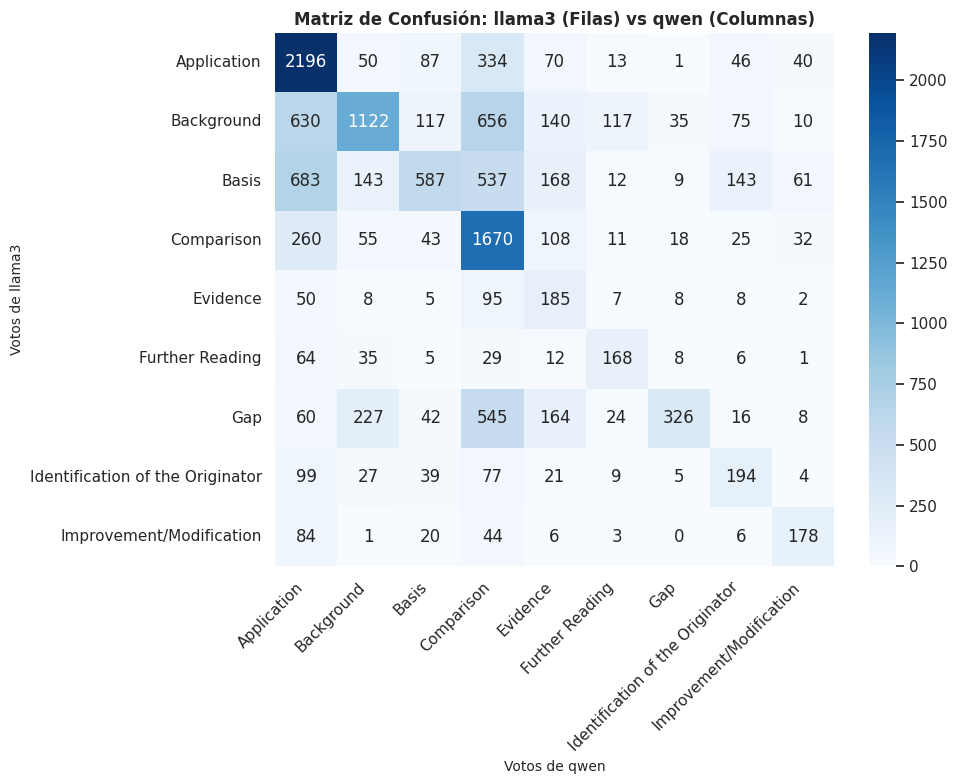

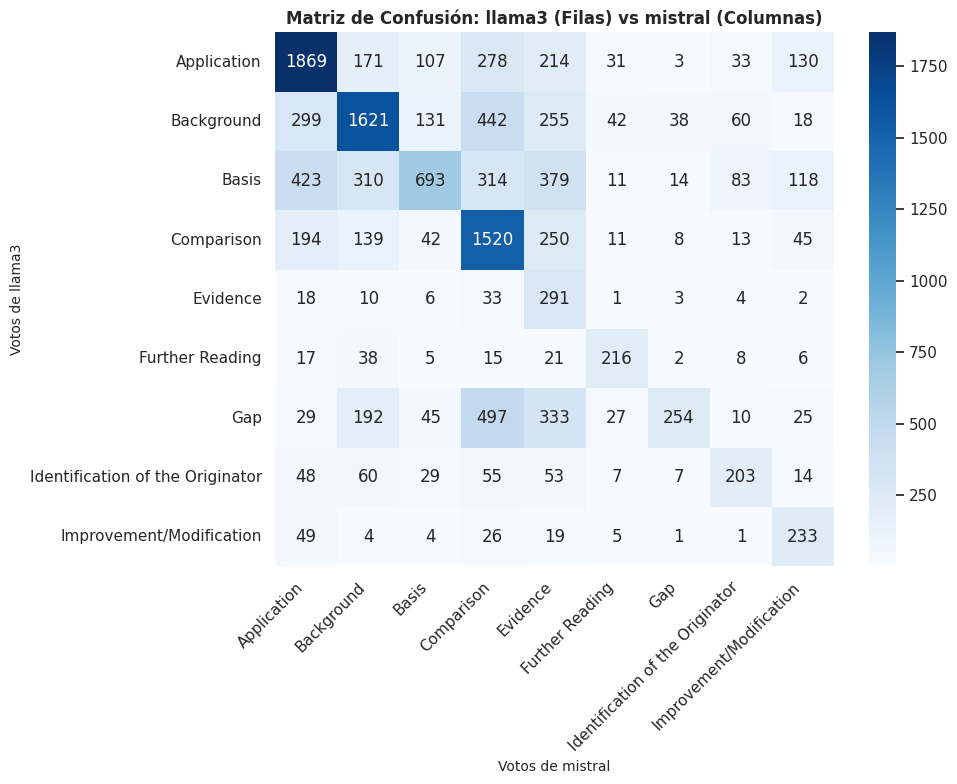

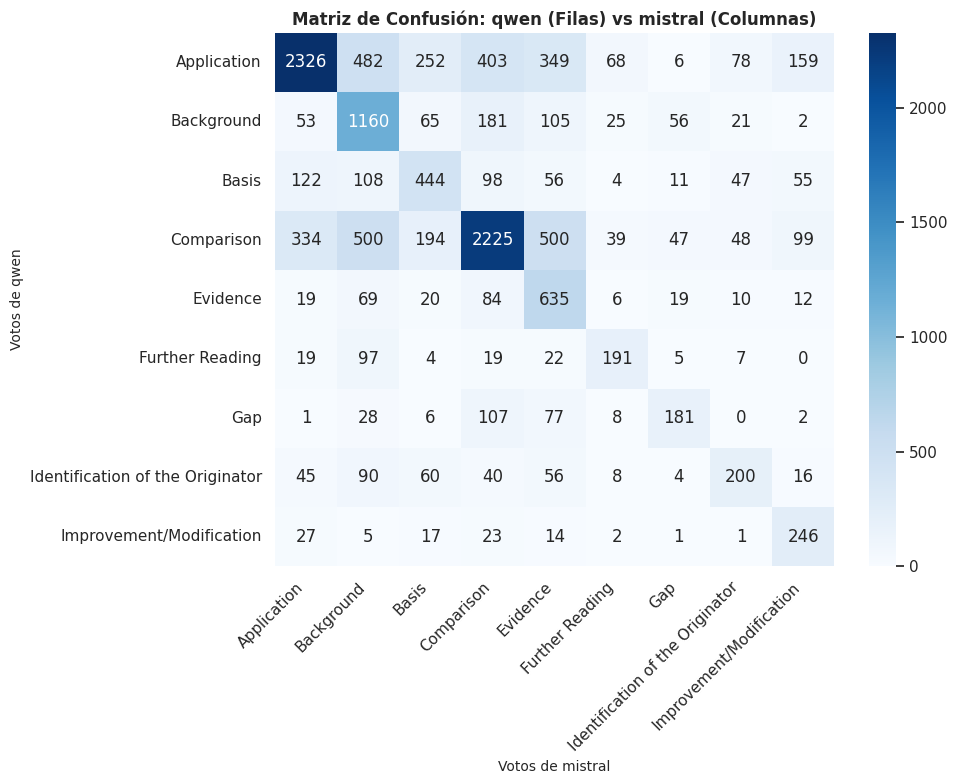

In [23]:
print("\nBOOTSTRAP")
if 'results' in globals() and results:
    disputed = [r for r in results if r["prelabel_agreement"] == "bootstrap"]
    if disputed:
        shares = [r["prelabel_confidence"] for r in disputed if r["prelabel_confidence"] is not None]
        win_ratio = sum(shares) / len(shares) if shares else 0.0

        changed = 0
        for r in disputed:
            top = max(r["prelabel_votes"].values())
            lead = [l for l, v in r["prelabel_votes"].items() if v == top]
            changed += len(lead) == 1 and lead[0] != r["prelabel_function"]

        bootstrap_data = {
            "Concepto": [
                "Citas con desacuerdo",
                "Proporción de victorias media de la categoría elegida",
                "Diferencia con la pluralidad simple (cuando existe una única)"
            ],
            "Valor": [len(disputed), round(win_ratio, 3), changed]
        }
        df_bootstrap = pd.DataFrame(bootstrap_data)
        display(df_bootstrap)

        print("\nMATRICES DE CONFUSIÓN ENTRE PARES DE JUECES")
        import sklearn.metrics as metrics
        import matplotlib.pyplot as plt
        import seaborn as sns

        names = [j.split("=")[0] for j in JUDGES]

        all_labels = sorted(list(LABELS))

        for i in range(len(names)):
            for k in range(i + 1, len(names)):
                j1, j2 = names[i], names[k]

                y_j1 = []
                y_j2 = []
                for r in results:
                    v1 = r["prelabel_judges"].get(j1, {}).get("function")
                    v2 = r["prelabel_judges"].get(j2, {}).get("function")
                    if v1 and v2:
                        y_j1.append(v1)
                        y_j2.append(v2)

                if y_j1 and y_j2:
                    cm = metrics.confusion_matrix(y_j1, y_j2, labels=all_labels)
                    cm_df = pd.DataFrame(cm, index=all_labels, columns=all_labels)

                    plt.figure(figsize=(10, 8))
                    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=True)
                    plt.title(f"Matriz de Confusión: {j1} (Filas) vs {j2} (Columnas)", fontsize=12, fontweight="bold")
                    plt.xlabel(f"Votos de {j2}", fontsize=10)
                    plt.ylabel(f"Votos de {j1}", fontsize=10)
                    plt.xticks(rotation=45, ha="right")
                    plt.tight_layout()
                    plt.show()
    else:
        print("No se encontraron citas en desacuerdo (bootstrap) para mostrar.")
else:
    print("No hay resultados cargados en la variable 'results'.")

In [24]:
print("\nCOBERTURA POR CATEGORÍA")
if 'results' in globals() and results:
    by = defaultdict(Counter)
    for r in results:
        if r.get("selected_function"):
            by[r["selected_function"]][r["prelabel_agreement"]] += 1

    cobertura_rows = []
    for l in LABELS:
        c = by[l]
        tot = sum(c.values())
        faltan = max(0, TARGET_PER_CLASS - tot)
        cobertura_rows.append({
            "Categoría": l,
            "Total": tot,
            "Unanimous": c['unanimous'],
            "Bootstrap": c['bootstrap'],
            "Unlabeled": c['unlabeled'],
            "Faltan para Objetivo (2000)": faltan
        })
    df_cobertura = pd.DataFrame(cobertura_rows)
    display(df_cobertura)
else:
    print("No hay resultados cargados en la variable 'results'.")


COBERTURA POR CATEGORÍA


,Categoría,Total,Unanimous,Bootstrap,Unlabeled,Faltan para Objetivo (2000)
0,Background,2193,744,1449,0,0
1,Gap,935,242,693,0,1065
2,Basis,1677,344,1333,0,323
3,Comparison,2128,898,1230,0,0
4,Application,2106,1118,988,0,0
5,Improvement/Modification,571,249,322,0,1429
6,Evidence,1425,351,1074,0,575
7,Identification of the Originator,800,362,438,0,1200
8,Further Reading,1408,687,721,0,592


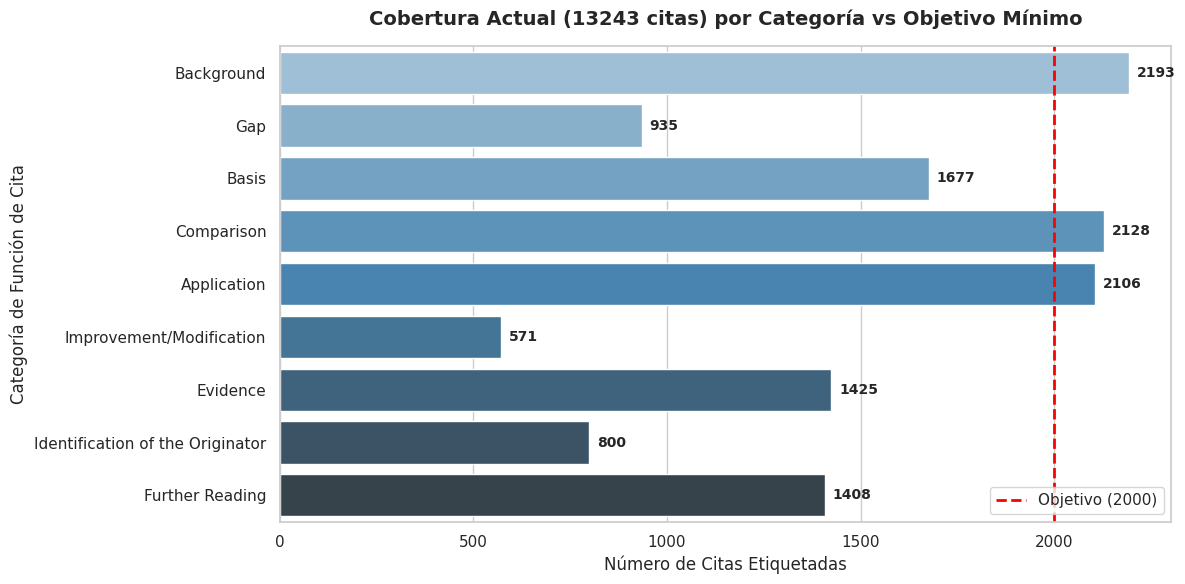

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

if 'df_cobertura' in globals():
    plt.figure(figsize=(12, 6))

    ax = sns.barplot(
        x="Total",
        y="Categoría",
        data=df_cobertura,
        palette="Blues_d",
        hue="Categoría",
        legend=False
    )

    plt.axvline(x=TARGET_PER_CLASS, color="red", linestyle="--", linewidth=2, label=f"Objetivo ({TARGET_PER_CLASS})")

    plt.title(f"Cobertura Actual ({len(results)} citas) por Categoría vs Objetivo Mínimo", fontsize=14, fontweight="bold", pad=15)
    plt.xlabel("Número de Citas Etiquetadas", fontsize=12)
    plt.ylabel("Categoría de Función de Cita", fontsize=12)
    plt.legend(loc="lower right")

    for p in ax.patches:
        width = p.get_width()
        ax.text(width + 20, p.get_y() + p.get_height()/2, f'{int(width)}', va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("El DataFrame df_cobertura no está disponible. Asegúrate de ejecutar la celda anterior.")

### 12. Distribución de funciones de cita por categoría arXiv

Clases con menos etiquetas:
selected_function
Background                          2193
Comparison                          2128
Application                         2106
Basis                               1677
Evidence                            1425
Further Reading                     1408
Gap                                  935
Identification of the Originator     800
Improvement/Modification             571
Name: count, dtype: int64

Citas por Categoría


selected_function,Application,Background,Basis,Comparison,Evidence,Further Reading,Gap,Identification of the Originator,Improvement/Modification
citing_category,,,,,,,,,
cs.CL,312,248,187,232,144,142,136,93,42
cs.LG,202,177,103,261,131,74,87,63,54
cs.AI,61,98,90,76,76,109,91,26,28
cs.CV,197,157,120,236,67,58,49,39,42
cs.SD,116,89,80,96,50,75,30,43,40
cs.IR,117,125,79,128,67,60,47,40,28
cs.NE,69,75,51,73,62,56,37,29,35
cs.CR,37,84,42,55,62,64,39,35,17
cs.NA,63,40,59,36,25,58,12,23,25


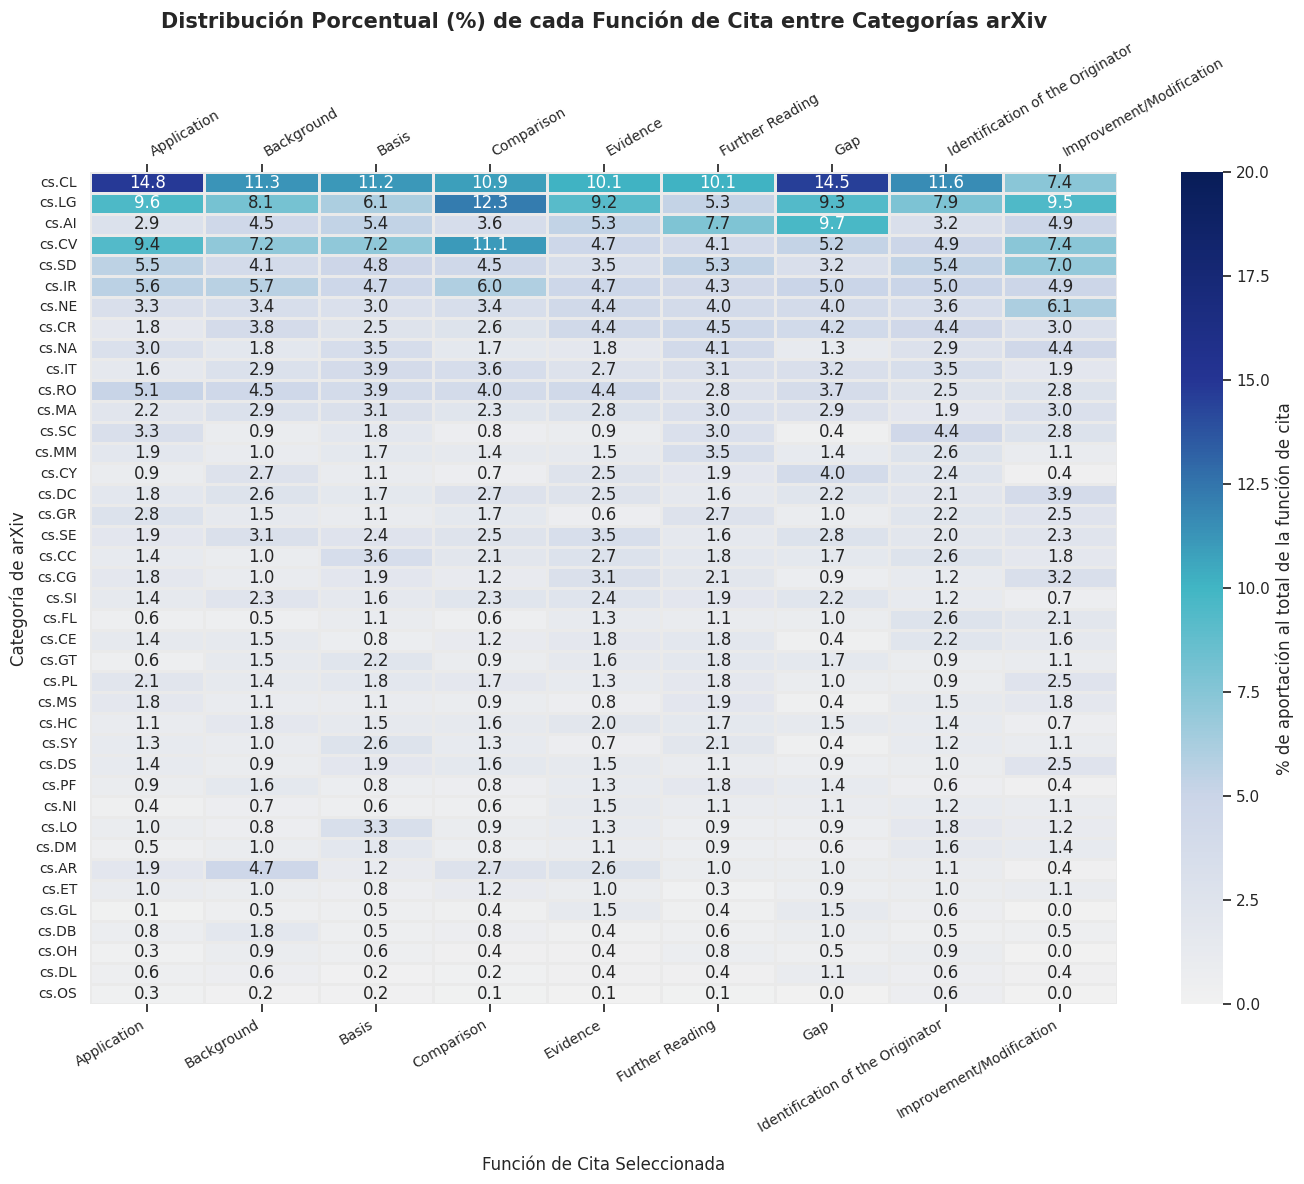

In [11]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

with open(OUTPUT_PATH, "r", encoding="utf-8") as f:
    data_labeled = json.load(f)
df_labeled = pd.DataFrame(data_labeled)

if "selected_function" in df_labeled.columns and "citing_category" in df_labeled.columns:
    clases_ordenadas_por_frecuencia = df_labeled["selected_function"].value_counts(ascending=True).index.tolist()
    clases_escasas = clases_ordenadas_por_frecuencia[:4]
    print(f"Clases con menos etiquetas:\n{df_labeled['selected_function'].value_counts()}\n")

    df_pivot = pd.crosstab(
        index=df_labeled["citing_category"],
        columns=df_labeled["selected_function"]
    )

    df_pivot["score_escasas"] = df_pivot[clases_escasas].sum(axis=1)

    df_pivot_sorted = df_pivot.sort_values(by="score_escasas", ascending=False).drop(columns=["score_escasas"])

    print("Citas por Categoría")
    display(df_pivot_sorted)

    df_pivot_percent = df_pivot_sorted.div(df_pivot_sorted.sum(axis=0), axis=1) * 100

    custom_colors = ["#f1f1f1", "#cbd5e8", "#41b6c4", "#253494", "#081d58"]
    custom_cmap = LinearSegmentedColormap.from_list("sensible_colors", custom_colors, N=256)

    plt.figure(figsize=(14, 12))
    sns.set_theme(style="white")

    ax = sns.heatmap(
        df_pivot_percent,
        annot=True,
        fmt=".1f",
        cmap=custom_cmap,
        linewidths=1.0,
        linecolor="#eaeaea",
        vmax=20.0,
        cbar_kws={'label': '% de aportación al total de la función de cita'}
    )

    plt.title("Distribución Porcentual (%) de cada Función de Cita entre Categorías arXiv", fontsize=15, fontweight="bold", pad=10)

    ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)

    for tick in ax.xaxis.get_major_ticks():
        tick.label1.set_fontsize(10)
        tick.label1.set_rotation(30)
        tick.label1.set_ha("right")

        tick.label2.set_fontsize(10)
        tick.label2.set_rotation(30)
        tick.label2.set_ha("left")

    plt.yticks(fontsize=10)

    plt.xlabel("Función de Cita Seleccionada", fontsize=12, labelpad=15)
    plt.ylabel("Categoría de arXiv", fontsize=12)

    plt.tight_layout()
    plt.show()
else:
    print("Error: Las columnas requeridas no están disponibles.")